# Term Project — Part 2
## Multimodal Depression Detection from Acoustic and Linguistic Features
### Data Splitting → Model Training & Tuning → Optimization → Evaluation → Final Pipeline

---

Part 1 turned the raw DAIC-WOZ interviews into participant-level features and explored them. This notebook completes the machine-learning pipeline and answers the four research questions of our proposal.

| | Research question | Section |
|---|---|---|
| **RQ1** | Do acoustic and linguistic features detect depression better than a majority-class baseline? | 5 |
| **RQ2** | Does multimodal fusion outperform the best single-modality model? | 6 |
| **RQ3** | Can a compact feature subset stay within ~2 macro-F1 points of the full feature set? | 8 |
| **RQ4** | How stable and interpretable are the selected features across data partitions? | 9 |

**Target:** official PHQ-8 binary label (PHQ-8 ≥ 10 = depressed). PHQ-8 scores and items are labels only, never inputs.

**Primary metric: macro-F1.** About 29 % of participants are depressed, so accuracy would reward predicting "not depressed" for everyone. Secondary metrics: ROC-AUC, balanced accuracy, and recall/precision of the depressed class (recall matters most for screening).

### Feature blocks (proposal §3 and §6)

| Block | Source | Features | Role |
|---|---|---|---|
| **Acoustic — hand-crafted** | Part 1 (`features_master.csv`): eGeMAPS (pitch, loudness, jitter, shimmer, HNR, formants, spectral), MFCC 1–13, COVAREP voice quality, formants, speaking rate and pauses — participant speech only | ≈ 128 | main |
| **Text — hand-crafted** | Part 1: word use, lexical diversity, turn length, psycholinguistic word categories — participant turns only | ≈ 17 | main |
| **Acoustic — wav2vec 2.0** | pre-computed self-supervised speech embeddings (mean ⊕ std over time) | 1536 | extension (proposal: "optional extension") |
| **Text — MentalBERT** | pre-computed contextual transformer embeddings of the transcript | 1536 | main ("transformer embeddings") |
| Video | Part 1: facial action units, head pose, gaze | ≈ 46 | supplementary only |

## 1. Environment and Configuration

In [1]:
import os, sys, time, json, warnings, importlib
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (f1_score, balanced_accuracy_score, roc_auc_score, precision_score,
                             recall_score, accuracy_score, confusion_matrix, roc_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 170)
SEED = 42
np.random.seed(SEED)

KAGGLE_ROOT = Path("/kaggle/input/datasets/malihashabbir/depressiondata")
ON_KAGGLE = KAGGLE_ROOT.exists()
DATA_ROOT = KAGGLE_ROOT if ON_KAGGLE else Path(os.environ.get("DAIC_ROOT", "D:/DAIC-WOZ"))
WORK_DIR = Path("/kaggle/working") if ON_KAGGLE else Path(".")
PART1_FEATURES = Path(os.environ.get("PART1_FEATURES", WORK_DIR / "part1_outputs" / "features_master.csv"))
OUT_DIR = WORK_DIR / "part2_outputs"
FIG_DIR, CACHE_DIR = OUT_DIR / "figures", OUT_DIR / "cache"
for d in (FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
sys.path.insert(0, str(WORK_DIR.resolve()))

print("Data root        :", DATA_ROOT.resolve())
print("Part 1 features  :", PART1_FEATURES.resolve(), "| exists:", PART1_FEATURES.exists())
print("Outputs          :", OUT_DIR.resolve())

Data root        : D:\DAIC-WOZ
Part 1 features  : C:\Users\HC\Desktop\Zaid\part1_outputs\features_master.csv | exists: True
Outputs          : C:\Users\HC\Desktop\Zaid\part2_outputs


The late-fusion model and the prediction script are written to small modules so that the saved model can be re-loaded outside this notebook.

In [2]:
%%writefile part2_models.py
"""Custom estimator used by Part 2 (kept in a module so saved models can be re-loaded)."""
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict


class LateFusion(BaseEstimator, ClassifierMixin):
    """Decision-level fusion.

    blocks: list of (name, column_indices, estimator, param_grid). Each block gets its own model,
    tuned by inner CV on that block's columns only.
    weighted=False -> average the block probabilities (equal weights).
    weighted=True  -> a logistic-regression stacker learns how much to trust each block from
                      out-of-fold block probabilities (speech and text are not assumed equal).
    """

    def __init__(self, blocks, weighted=False, seed=42):
        self.blocks = blocks
        self.weighted = weighted
        self.seed = seed

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_ = np.unique(y)
        inner = StratifiedKFold(5, shuffle=True, random_state=self.seed)
        self.models_, oofs = [], []
        for name, cols, est, grid in self.blocks:
            gs = GridSearchCV(clone(est), grid, scoring="f1_macro", cv=inner, n_jobs=-1).fit(X[:, cols], y)
            self.models_.append(gs.best_estimator_)
            if self.weighted:
                oofs.append(cross_val_predict(clone(gs.best_estimator_), X[:, cols], y, cv=inner,
                                              method="predict_proba", n_jobs=-1)[:, 1])
        if self.weighted:
            self.stacker_ = LogisticRegression(class_weight="balanced", random_state=self.seed)
            self.stacker_.fit(np.column_stack(oofs), y)
        return self

    def block_probas(self, X):
        X = np.asarray(X, dtype=float)
        return np.column_stack([m.predict_proba(X[:, b[1]])[:, 1] for m, b in zip(self.models_, self.blocks)])

    def predict_proba(self, X):
        P = self.block_probas(X)
        p = self.stacker_.predict_proba(P)[:, 1] if self.weighted else P.mean(axis=1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

Overwriting part2_models.py


In [3]:
%%writefile predict.py
"""Depression screening prediction for unseen participants.

Usage:
    python predict.py --features-dir <dir> [<dir> ...] [--model part2_outputs/final_model.joblib] [--out predictions.csv]

The directories must contain the participant-level feature files the saved model needs, in the same
format as the training data (one row per participant, column `participant_id`):
  - features_master.csv                     (hand-crafted features, produced by Part 1's extraction)
  - DAIC_WOZ_wav2vec2_temporal_1536.csv     (only if the model uses wav2vec2)
  - DAIC_WOZ_MentalBERT_1536.csv            (only if the model uses MentalBERT)
Output: participant_id, probability of depression, screening decision (1 = flag for clinical follow-up).
This is a screening aid, not a diagnosis.
"""
import argparse
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

import part2_models  # noqa: F401  (needed to un-pickle LateFusion)


def _find(dirs, fname):
    for d in dirs:
        p = Path(d) / fname
        if p.exists():
            return p
    raise FileNotFoundError(f"{fname} not found in {list(map(str, dirs))}")


def load_features(dirs, sources):
    frames = []
    for fname, cols in sources.items():
        df = pd.read_csv(_find(dirs, fname)).set_index("participant_id")
        missing = [c for c in cols if c not in df.columns]
        if missing:
            raise ValueError(f"{fname}: {len(missing)} expected columns missing, e.g. {missing[:5]}")
        frames.append(df[cols])
    return pd.concat(frames, axis=1, join="inner")


def predict(features_dirs, model_path="part2_outputs/final_model.joblib", ids=None):
    bundle = joblib.load(model_path)
    if isinstance(features_dirs, (str, Path)):
        features_dirs = [features_dirs]
    feats = load_features(features_dirs, bundle["sources"])
    if ids is not None:
        feats = feats.loc[list(ids)]
    X = feats[bundle["columns"]].values.astype(float)
    prob = bundle["model"].predict_proba(X)[:, 1]
    return pd.DataFrame({"participant_id": feats.index,
                         "probability_depressed": np.round(prob, 4),
                         "screen_positive": (prob >= bundle["threshold"]).astype(int)})


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--features-dir", nargs="+", required=True)
    ap.add_argument("--model", default="part2_outputs/final_model.joblib")
    ap.add_argument("--out", default=None)
    a = ap.parse_args()
    res = predict(a.features_dir, a.model)
    print(res.to_string(index=False))
    if a.out:
        res.to_csv(a.out, index=False)
        print("saved", a.out)

Overwriting predict.py


## 2. Load Features and Labels

In [4]:
p1 = pd.read_csv(PART1_FEATURES).set_index("participant_id").sort_index()
emb = {"acoustic_w2v": "DAIC_WOZ_wav2vec2_temporal_1536.csv", "text_bert": "DAIC_WOZ_MentalBERT_1536.csv"}
P1_FILE = "features_master.csv"

block_cols, block_file, frames = {}, {}, []
p1_prefix = {"acoustic_hc": ("eg_", "mfcc", "cov_", "fmt_", "tm_"), "text_hc": ("tx_",), "video": ("vid_",)}
for b, pref in p1_prefix.items():
    block_cols[b] = [c for c in p1.columns if c.startswith(pref)]
    block_file[b] = P1_FILE
frames.append(p1.drop(columns="split"))
split = p1["split"]
for b, f in emb.items():
    df = pd.read_csv(DATA_ROOT / f).set_index("participant_id").sort_index()
    assert df.index.equals(split.index) and (df["split"] == split).all(), f"{b}: participant/split mismatch"
    df = df.drop(columns="split")
    block_cols[b], block_file[b] = list(df.columns), f
    frames.append(df)
features = pd.concat(frames, axis=1)
assert features.columns.is_unique

BLOCK_LABEL = {"acoustic_hc": "Acoustic (hand-crafted)", "acoustic_w2v": "Acoustic (wav2vec2)",
               "text_hc": "Text (hand-crafted)", "text_bert": "Text (MentalBERT)", "video": "Video"}
for b in BLOCK_LABEL:
    print(f"{BLOCK_LABEL[b]:26s} {len(block_cols[b]):5d} features   ({block_file[b]})")
miss = features.isna().sum()
print(f"\nFeature table: {features.shape[0]} participants × {features.shape[1]} features; "
      f"missing cells: {int(miss.sum())} in {dict(miss[miss > 0])} (imputed inside training folds)")

Acoustic (hand-crafted)      128 features   (features_master.csv)
Acoustic (wav2vec2)         1536 features   (DAIC_WOZ_wav2vec2_temporal_1536.csv)
Text (hand-crafted)           17 features   (features_master.csv)
Text (MentalBERT)           1536 features   (DAIC_WOZ_MentalBERT_1536.csv)
Video                         46 features   (features_master.csv)

Feature table: 188 participants × 3263 features; missing cells: 9 in {'tm_latency_mean_s': np.int64(3), 'tm_latency_median_s': np.int64(3), 'tm_latency_std_s': np.int64(3)} (imputed inside training folds)


In [5]:
tr = pd.read_csv(DATA_ROOT / "train_split_Depression_AVEC2017.csv")
dv = pd.read_csv(DATA_ROOT / "dev_split_Depression_AVEC2017.csv")
ts = pd.read_csv(DATA_ROOT / "full_test_split.csv")
lab = pd.concat([
    tr[["Participant_ID", "PHQ8_Binary", "Gender"]].set_axis(["participant_id", "y", "gender"], axis=1),
    dv[["Participant_ID", "PHQ8_Binary", "Gender"]].set_axis(["participant_id", "y", "gender"], axis=1),
    ts[["Participant_ID", "PHQ_Binary", "Gender"]].set_axis(["participant_id", "y", "gender"], axis=1),
]).set_index("participant_id")
meta = split.to_frame().join(lab)
assert meta["y"].notna().all()
meta["y"] = meta["y"].astype(int)

## 3. Data Splitting (training / validation / test)

| Set | Participants | Used for |
|---|---|---|
| **Development pool** = official train (107) + dev (34) | 141 | all training, tuning and model comparison |
| ↳ outer CV folds (5 folds × 2 repeats) | ≈ 113 train / 28 validation per fold | honest estimate of each candidate's performance |
| ↳ inner CV folds (5 folds, inside each outer training part) | ≈ 90 / 23 | hyper-parameter tuning and decision-threshold choice |
| **Official test split** | 47 | touched **once**, at the end, for two pre-declared models |

**Why not just train on "train" and validate on "dev"?** With 34 dev participants (11 depressed) a single validation split is extremely noisy — one person changes macro-F1 by several points. Nested cross-validation uses all 141 participants for both training and validation while never letting a participant be in the training and validation part of the same fold. This is the split design stated in the proposal. All splits are **stratified** (same depressed share in every fold) and at **participant level** (one row per participant).

,participants,depressed,share depressed
pool,,,
development (train+dev),141,41,0.291
test,47,14,0.298


fold,0,1,2,3,4,5,6,7,8,9
train n,112.0,113.0,113.0,113.0,113.0,112.0,113.0,113.0,113.0,113.0
validation n,29.0,28.0,28.0,28.0,28.0,29.0,28.0,28.0,28.0,28.0
train % depressed,28.6,29.2,29.2,29.2,29.2,28.6,29.2,29.2,29.2,29.2
validation % depressed,31.0,28.6,28.6,28.6,28.6,31.0,28.6,28.6,28.6,28.6


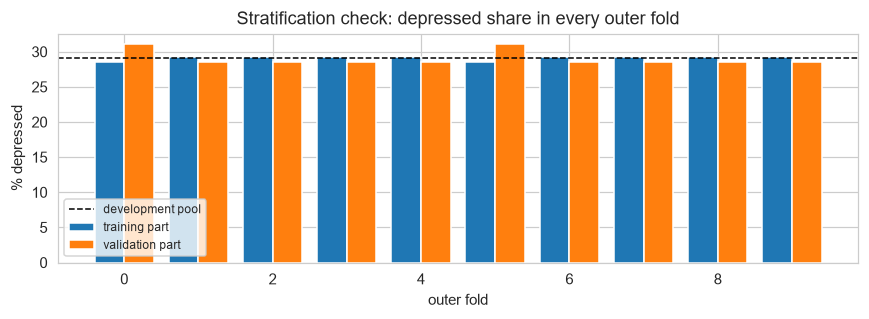

In [6]:
DEV_IDS = meta.index[meta["split"] != "test"]
TEST_IDS = meta.index[meta["split"] == "test"]
y_dev, y_test = meta.loc[DEV_IDS, "y"].values, meta.loc[TEST_IDS, "y"].values
OUTER = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

tab = meta.assign(pool=np.where(meta["split"] == "test", "test", "development (train+dev)")) \
          .groupby("pool")["y"].agg(participants="size", depressed="sum")
tab["share depressed"] = (tab["depressed"] / tab["participants"]).round(3)
display(tab)

fold_rows = []
for i, (a, b) in enumerate(OUTER.split(np.zeros(len(y_dev)), y_dev)):
    fold_rows.append({"fold": i, "train n": len(a), "validation n": len(b),
                      "train % depressed": 100 * y_dev[a].mean(), "validation % depressed": 100 * y_dev[b].mean()})
folds = pd.DataFrame(fold_rows).set_index("fold")
display(folds.round(1).T)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(folds.index - 0.2, folds["train % depressed"], 0.4, label="training part")
ax.bar(folds.index + 0.2, folds["validation % depressed"], 0.4, label="validation part")
ax.axhline(100 * y_dev.mean(), color="k", ls="--", lw=1, label="development pool")
ax.set_xlabel("outer fold"); ax.set_ylabel("% depressed"); ax.set_title("Stratification check: depressed share in every outer fold")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / "03_split_stratification.png", bbox_inches="tight"); plt.show()

### 3.1 Feature sets compared

In [7]:
MODALITIES = {
    "acoustic_hc":  ["acoustic_hc"],
    "acoustic_w2v": ["acoustic_w2v"],
    "acoustic":     ["acoustic_hc", "acoustic_w2v"],
    "text_hc":      ["text_hc"],
    "text_bert":    ["text_bert"],
    "text":         ["text_hc", "text_bert"],
    "handcrafted":  ["acoustic_hc", "text_hc"],
    "early_fusion": ["acoustic_hc", "acoustic_w2v", "text_hc", "text_bert"],
    "video":        ["video"],
}
MOD_LABEL = {"acoustic_hc": "Acoustic: hand-crafted", "acoustic_w2v": "Acoustic: wav2vec2", "acoustic": "Acoustic: all",
             "text_hc": "Text: hand-crafted", "text_bert": "Text: MentalBERT", "text": "Text: all",
             "handcrafted": "Fusion: hand-crafted (speech+text)", "early_fusion": "Fusion: all (speech+text)",
             "video": "Video (supplementary)"}
SINGLE = ["acoustic_hc", "acoustic_w2v", "acoustic", "text_hc", "text_bert", "text"]

def cols_of(mod):
    return [c for b in MODALITIES[mod] for c in block_cols[b]]
def Xdev(mod):
    return features.loc[DEV_IDS, cols_of(mod)].values.astype(float)
def Xtest(mod):
    return features.loc[TEST_IDS, cols_of(mod)].values.astype(float)

display(pd.DataFrame({"blocks": [" + ".join(BLOCK_LABEL[b] for b in MODALITIES[m]) for m in MODALITIES],
                      "features": [len(cols_of(m)) for m in MODALITIES]}, index=[MOD_LABEL[m] for m in MODALITIES]))

,blocks,features
Acoustic: hand-crafted,Acoustic (hand-crafted),128
Acoustic: wav2vec2,Acoustic (wav2vec2),1536
Acoustic: all,Acoustic (hand-crafted) + Acoustic (wav2vec2),1664
Text: hand-crafted,Text (hand-crafted),17
Text: MentalBERT,Text (MentalBERT),1536
Text: all,Text (hand-crafted) + Text (MentalBERT),1553
Fusion: hand-crafted (speech+text),Acoustic (hand-crafted) + Text (hand-crafted),145
Fusion: all (speech+text),Acoustic (hand-crafted) + Acoustic (wav2vec2) ...,3217
Video (supplementary),Video,46


## 4. Model Selection and Implementation

**Candidate models** (proposal §6) — chosen to cover different inductive biases on a small, high-dimensional dataset:

| Model | Why it is a candidate | Tuned hyper-parameters |
|---|---|---|
| Logistic regression (L2) | strong linear baseline, well-calibrated probabilities, robust when features ≫ samples | C (regularization) |
| RBF-SVM | non-linear boundaries with strong regularization; standard on DAIC-WOZ | C |
| Random forest | non-linear, insensitive to scaling and outliers, gives feature importances | max depth, min samples per leaf |
| Gradient boosting (histogram) | strongest tabular learner in general; tests whether boosting helps at n ≈ 140 | learning rate, max depth |

**Every model is a single pipeline**, so all learned preprocessing is re-fitted inside each training fold:
`median imputation → drop constant columns → standardize → [feature selection] → [SMOTE] → classifier`.

**Class imbalance** is handled by **class weighting** (default) or **SMOTE** (synthetic minority oversampling, applied to training folds only).

**Decision threshold.** The probability cut-off is tuned too: inside each training part, the threshold that maximizes macro-F1 on *out-of-fold* predictions is chosen and then applied unchanged to the validation fold.

In [8]:
THR_GRID = np.round(np.arange(0.10, 0.91, 0.01), 2)

def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"macro_f1": f1_score(y_true, pred, average="macro"),
            "auc": roc_auc_score(y_true, prob) if len(np.unique(y_true)) > 1 else np.nan,
            "bal_acc": balanced_accuracy_score(y_true, pred),
            "recall_dep": recall_score(y_true, pred, zero_division=0),
            "precision_dep": precision_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

def best_threshold(y_true, prob):
    s = [f1_score(y_true, (prob >= t).astype(int), average="macro") for t in THR_GRID]
    return float(THR_GRID[int(np.argmax(s))])

def make_pipe(clf, imbalance="class_weight", k=None):
    steps = [("impute", SimpleImputer(strategy="median")), ("var", VarianceThreshold(1e-8)), ("scale", StandardScaler())]
    if k is not None:
        steps.append(("select", SelectKBest(f_classif, k=k)))
    if imbalance == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", clf))
    return ImbPipeline(steps)

def classifiers(imbalance="class_weight"):
    cw = "balanced" if imbalance == "class_weight" else None
    return {
        "logreg": (LogisticRegression(max_iter=5000, class_weight=cw, random_state=SEED),
                   {"clf__C": [0.001, 0.01, 0.1, 1.0]}),
        "svm":    (SVC(kernel="rbf", probability=True, class_weight=cw, random_state=SEED),
                   {"clf__C": [0.1, 1.0, 10.0]}),
        "rf":     (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1,
                                          class_weight="balanced_subsample" if cw else None),
                   {"clf__max_depth": [3, None], "clf__min_samples_leaf": [1, 5]}),
        "gboost": (HistGradientBoostingClassifier(max_iter=150, early_stopping=False, class_weight=cw, random_state=SEED),
                   {"clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 4]}),
    }
CLF_LABEL = {"logreg": "Logistic regression", "svm": "RBF-SVM", "rf": "Random forest", "gboost": "Gradient boosting"}

def model_spec(mod, clf_name, imbalance="class_weight", k=None):
    clf, grid = classifiers(imbalance)[clf_name]
    if k is not None and k >= len(cols_of(mod)):
        k = None
    return make_pipe(clf, imbalance, k), grid

def n_features_used(model):
    if not hasattr(model, "named_steps"):
        return np.nan
    n = int(model.named_steps["var"].get_support().sum())
    if "select" in model.named_steps:
        n = int(model.named_steps["select"].get_support().sum())
    clf = model.named_steps["clf"]
    if getattr(clf, "penalty", None) == "l1":
        n = int((clf.coef_ != 0).sum())
    return n

def fit_tuned(est, grid, X, y, tune_threshold=True, seed=SEED):
    inner = StratifiedKFold(5, shuffle=True, random_state=seed)
    if grid:
        gs = GridSearchCV(est, grid, scoring="f1_macro", cv=inner, n_jobs=-1).fit(X, y)
        best, params = gs.best_estimator_, gs.best_params_
    else:
        best, params = clone(est).fit(X, y), {}
    if not tune_threshold:
        return best, 0.5, params
    oof = cross_val_predict(clone(best), X, y, cv=inner, method="predict_proba", n_jobs=-1)[:, 1]
    return best, best_threshold(y, oof), params

PRED = {}   # name -> out-of-fold validation predictions (for subgroup analysis)
def nested_cv(name, est, grid, X, tune_threshold=True):
    path, ppath = CACHE_DIR / f"{name}.csv", CACHE_DIR / f"{name}__pred.csv"
    if path.exists() and ppath.exists():
        PRED[name] = pd.read_csv(ppath)
        df = pd.read_csv(path); df.attrs["cache_name"] = name
        return df
    rows, preds = [], []
    for i, (tr_i, te_i) in enumerate(OUTER.split(X, y_dev)):
        best, thr, params = fit_tuned(est, grid, X[tr_i], y_dev[tr_i], tune_threshold)
        p = best.predict_proba(X[te_i])[:, 1]
        rows.append({"fold": i, "threshold": thr, "n_features": n_features_used(best),
                     "params": json.dumps(params, default=str), **metrics(y_dev[te_i], p, thr)})
        preds.append(pd.DataFrame({"fold": i, "participant_id": DEV_IDS[te_i], "prob": p, "threshold": thr}))
    df = pd.DataFrame(rows); df.to_csv(path, index=False)
    PRED[name] = pd.concat(preds); PRED[name].to_csv(ppath, index=False)
    df.attrs["cache_name"] = name
    return df

def summarize(df):
    return {"macro_f1": df["macro_f1"].mean(), "macro_f1_sd": df["macro_f1"].std(), "auc": df["auc"].mean(),
            "bal_acc": df["bal_acc"].mean(), "recall_dep": df["recall_dep"].mean(),
            "precision_dep": df["precision_dep"].mean(), "n_features": df["n_features"].mean()}

RESULTS = {}

## 5. Model Training, Hyper-parameter Tuning and RQ1

**RQ1 — do acoustic and linguistic features beat the majority baseline?** Every feature set is trained with all four classifiers (class weighting, inner-CV tuning, tuned threshold) on identical outer folds. For each feature set's best classifier we also try SMOTE instead of class weighting.

In [9]:
maj = []
for i, (a, b) in enumerate(OUTER.split(np.zeros(len(y_dev)), y_dev)):
    maj.append({"fold": i, "threshold": 0.5, "n_features": 0, "params": "{}", **metrics(y_dev[b], np.zeros(len(b)), 0.5)})
RESULTS["majority"] = pd.DataFrame(maj); RESULTS["majority"]["auc"] = 0.5

t0 = time.time()
for mod in MODALITIES:
    for clf_name in classifiers():
        est, grid = model_spec(mod, clf_name)
        RESULTS[f"{mod}|{clf_name}|cw"] = nested_cv(f"rq1_{mod}_{clf_name}_cw", est, grid, Xdev(mod))
    print(f"  {MOD_LABEL[mod]:36s} done ({time.time() - t0:5.0f}s)")

  Acoustic: hand-crafted               done (    0s)


  Acoustic: wav2vec2                   done (    0s)


  Acoustic: all                        done (    1s)
  Text: hand-crafted                   done (    1s)


  Text: MentalBERT                     done (    1s)


  Text: all                            done (    1s)
  Fusion: hand-crafted (speech+text)   done (    1s)


  Fusion: all (speech+text)            done (    2s)
  Video (supplementary)                done (    2s)


In [10]:
def table(names):
    rows = []
    for n in names:
        mod, clf, imb = n.split("|")
        rows.append({"candidate": n, "features": MOD_LABEL[mod], "model": CLF_LABEL[clf],
                     "imbalance": {"cw": "class weight", "smote": "SMOTE"}[imb], **summarize(RESULTS[n])})
    return pd.DataFrame(rows).set_index("candidate")

rq1 = table([n for n in RESULTS if n.count("|") == 2])
BEST0 = rq1.loc[rq1.groupby("features")["macro_f1"].idxmax()]
for cand in BEST0.index:
    mod, clf_name, _ = cand.split("|")
    est, grid = model_spec(mod, clf_name, "smote")
    RESULTS[f"{mod}|{clf_name}|smote"] = nested_cv(f"rq1_{mod}_{clf_name}_smote", est, grid, Xdev(mod))

rq1 = table([n for n in RESULTS if n.count("|") == 2])
rq1.round(4).to_csv(OUT_DIR / "rq1_all_candidates.csv")
best_rows = rq1.loc[rq1.groupby("features")["macro_f1"].idxmax()].sort_values("macro_f1", ascending=False)
BEST_CFG = {c.split("|")[0]: c for c in best_rows.index}
show = ["features", "model", "imbalance", "macro_f1", "macro_f1_sd", "auc", "recall_dep", "precision_dep"]
print(f"Majority baseline macro-F1: {RESULTS['majority']['macro_f1'].mean():.3f}\n\nBest configuration per feature set:")
display(best_rows[show].round(3))

Majority baseline macro-F1: 0.415

Best configuration per feature set:


,features,model,imbalance,macro_f1,macro_f1_sd,auc,recall_dep,precision_dep
candidate,,,,,,,,
early_fusion|logreg|smote,Fusion: all (speech+text),Logistic regression,SMOTE,0.732,0.087,0.792,0.601,0.650
text|svm|cw,Text: all,RBF-SVM,class weight,0.697,0.098,0.734,0.562,0.607
text_bert|svm|cw,Text: MentalBERT,RBF-SVM,class weight,0.695,0.090,0.737,0.562,0.592
acoustic|logreg|cw,Acoustic: all,Logistic regression,class weight,0.613,0.053,0.673,0.479,0.481
acoustic_w2v|logreg|smote,Acoustic: wav2vec2,Logistic regression,SMOTE,0.573,0.066,0.646,0.467,0.413
acoustic_hc|logreg|cw,Acoustic: hand-crafted,Logistic regression,class weight,0.572,0.095,0.614,0.440,0.416
handcrafted|logreg|cw,Fusion: hand-crafted (speech+text),Logistic regression,class weight,0.569,0.096,0.640,0.464,0.423
text_hc|logreg|cw,Text: hand-crafted,Logistic regression,class weight,0.514,0.122,0.564,0.454,0.356
video|svm|cw,Video (supplementary),RBF-SVM,class weight,0.487,0.065,0.607,0.332,0.242


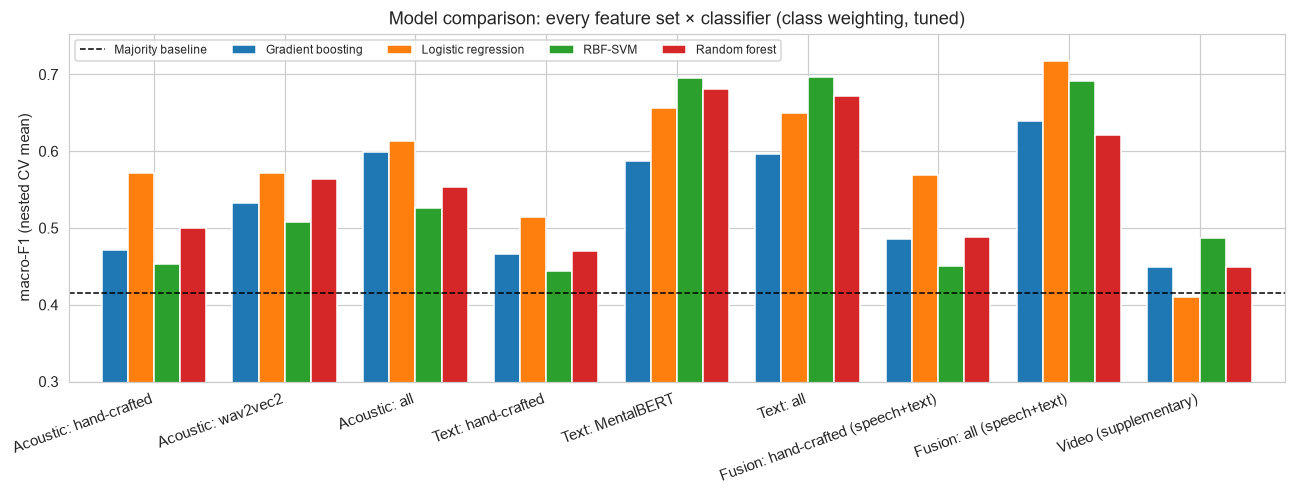

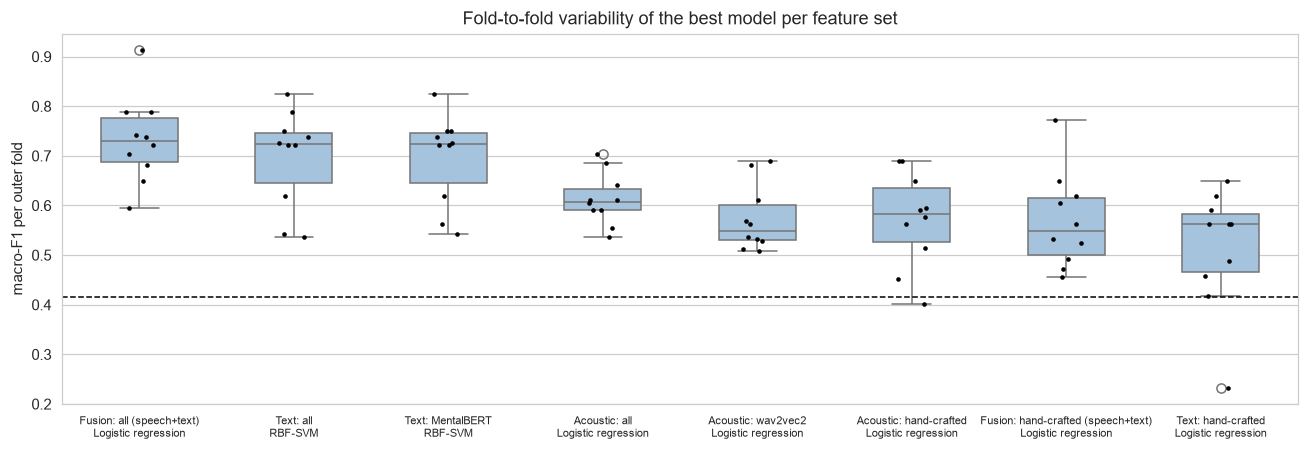

In [11]:
fig, ax = plt.subplots(figsize=(12, 4.6))
piv = rq1[rq1["imbalance"] == "class weight"].pivot(index="features", columns="model", values="macro_f1")
piv = piv.loc[[MOD_LABEL[m] for m in MODALITIES]]
piv.plot.bar(ax=ax, rot=20, width=0.8)
ax.axhline(RESULTS["majority"]["macro_f1"].mean(), color="k", ls="--", lw=1, label="Majority baseline")
ax.set_ylabel("macro-F1 (nested CV mean)"); ax.set_xlabel(""); ax.set_ylim(0.3, None)
ax.set_title("Model comparison: every feature set × classifier (class weighting, tuned)")
ax.legend(fontsize=8, ncol=5, loc="upper left"); plt.xticks(ha="right")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_model_comparison.png", bbox_inches="tight"); plt.show()

# Fold-level spread of the best candidates (performance analysis)
top8 = best_rows.index[:8]
long = pd.concat([RESULTS[n].assign(candidate=f"{rq1.loc[n, 'features']}\n{rq1.loc[n, 'model']}") for n in top8])
fig, ax = plt.subplots(figsize=(12, 4.2))
sns.boxplot(data=long, x="candidate", y="macro_f1", ax=ax, color="#9dc3e6", width=0.5)
sns.stripplot(data=long, x="candidate", y="macro_f1", ax=ax, color="k", size=3)
ax.axhline(RESULTS["majority"]["macro_f1"].mean(), color="k", ls="--", lw=1)
ax.set_xlabel(""); ax.set_ylabel("macro-F1 per outer fold"); ax.set_title("Fold-to-fold variability of the best model per feature set")
ax.tick_params(axis="x", labelsize=7.5)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_fold_variability.png", bbox_inches="tight"); plt.show()

In [12]:
# Hyper-parameters chosen by the inner loop (most frequent value across the 10 outer folds)
hp = []
for n in best_rows.index:
    ps = RESULTS[n]["params"].map(json.loads)
    keys = sorted({k for p in ps for k in p})
    hp.append({"features": rq1.loc[n, "features"], "model": rq1.loc[n, "model"],
               **{k.replace("clf__", ""): pd.Series([p.get(k) for p in ps]).astype(str).value_counts().index[0] for k in keys},
               "median threshold": RESULTS[n]["threshold"].median()})
display(pd.DataFrame(hp).set_index("features").fillna("—"))

,model,C,median threshold
features,,,
Fusion: all (speech+text),Logistic regression,0.01,0.470
Text: all,RBF-SVM,1.0,0.355
Text: MentalBERT,RBF-SVM,1.0,0.345
Acoustic: all,Logistic regression,0.01,0.530
Acoustic: wav2vec2,Logistic regression,0.001,0.520
Acoustic: hand-crafted,Logistic regression,1.0,0.515
Fusion: hand-crafted (speech+text),Logistic regression,0.1,0.515
Text: hand-crafted,Logistic regression,0.01,0.500
Video (supplementary),RBF-SVM,10.0,0.325


## 6. Comparison of Fusion Approaches (RQ2)

**RQ2 — does fusing speech and text beat the best single modality?**

| Design | How it works |
|---|---|
| **Early fusion (hand-crafted)** | concatenate hand-crafted acoustic + text features, one model (from Section 5) |
| **Early fusion (all)** | concatenate all four speech and text blocks, one model (from Section 5) |
| **Late fusion (equal)** | one model per block (best RQ1 configuration, re-tuned in every fold); average the four probabilities |
| **Weighted late fusion** | same block models; a logistic-regression *stacker* learns block weights from out-of-fold predictions — speech and text are **not** assumed to contribute equally |

In [13]:
import part2_models
importlib.reload(part2_models)
from part2_models import LateFusion

FUSION_BLOCKS = ["acoustic_hc", "acoustic_w2v", "text_hc", "text_bert"]
X_fusion = Xdev("early_fusion")          # columns ordered as FUSION_BLOCKS

def block_specs():
    specs, start = [], 0
    for b in FUSION_BLOCKS:
        n = len(block_cols[b])
        mod, clf_name, imb = BEST_CFG[b].split("|")
        est, grid = model_spec(mod, clf_name, "smote" if imb == "smote" else "class_weight")
        specs.append((b, np.arange(start, start + n), est, grid))
        start += n
    return specs

for weighted in (False, True):
    name = "late_fusion_weighted" if weighted else "late_fusion_equal"
    t0 = time.time()
    RESULTS[name] = nested_cv(f"rq2_{name}", LateFusion(block_specs(), weighted=weighted, seed=SEED), {}, X_fusion)
    print(f"{name} done ({time.time() - t0:.0f}s)")

late_fusion_equal done (0s)
late_fusion_weighted done (0s)


,macro_f1,macro_f1_sd,auc,recall_dep,precision_dep,candidate
Majority baseline,0.415,0.004,0.500,0.000,0.000,majority
Acoustic: hand-crafted,0.572,0.095,0.614,0.440,0.416,acoustic_hc|logreg|cw
Acoustic: wav2vec2,0.573,0.066,0.646,0.467,0.413,acoustic_w2v|logreg|smote
Acoustic: all,0.613,0.053,0.673,0.479,0.481,acoustic|logreg|cw
Text: hand-crafted,0.514,0.122,0.564,0.454,0.356,text_hc|logreg|cw
Text: MentalBERT,0.695,0.090,0.737,0.562,0.592,text_bert|svm|cw
Text: all,0.697,0.098,0.734,0.562,0.607,text|svm|cw
Early fusion (hand-crafted),0.569,0.096,0.640,0.464,0.423,handcrafted|logreg|cw
Early fusion (all),0.732,0.087,0.792,0.601,0.650,early_fusion|logreg|smote
Late fusion (equal),0.619,0.067,0.710,0.571,0.542,late_fusion_equal


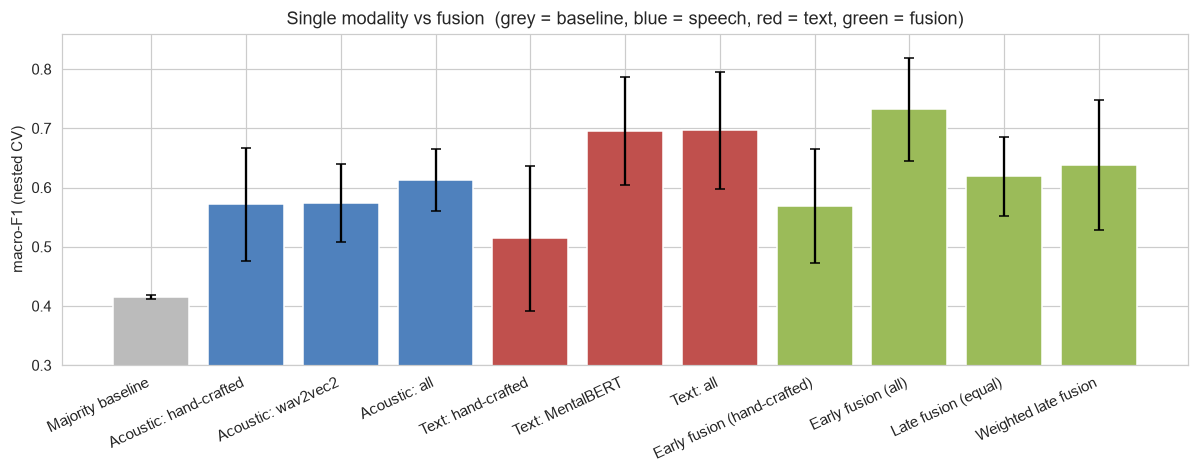

Paired, fold-by-fold comparison against the best single modality (Text: all):


,mean difference vs best single,folds better,folds worse
fusion design,,,
Early fusion (hand-crafted),-0.128,2,8
Early fusion (all),0.036,6,4
Late fusion (equal),-0.077,2,8
Weighted late fusion,-0.058,3,7


In [14]:
cands = {"Majority baseline": "majority"}
cands.update({f"{MOD_LABEL[m]}": BEST_CFG[m] for m in SINGLE})
cands.update({"Early fusion (hand-crafted)": BEST_CFG["handcrafted"], "Early fusion (all)": BEST_CFG["early_fusion"],
              "Late fusion (equal)": "late_fusion_equal", "Weighted late fusion": "late_fusion_weighted"})
rq2 = pd.DataFrame({k: summarize(RESULTS[v]) for k, v in cands.items()}).T
rq2["candidate"] = list(cands.values())
display(rq2[["macro_f1", "macro_f1_sd", "auc", "recall_dep", "precision_dep", "candidate"]].round(3))
rq2.round(4).to_csv(OUT_DIR / "rq2_fusion.csv")

colors = ["#bbbbbb"] + ["#4f81bd"] * 3 + ["#c0504d"] * 3 + ["#9bbb59"] * 4
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(rq2.index, rq2["macro_f1"], yerr=rq2["macro_f1_sd"], color=colors, capsize=3)
ax.set_ylabel("macro-F1 (nested CV)"); ax.set_ylim(0.3, None)
ax.set_title("Single modality vs fusion  (grey = baseline, blue = speech, red = text, green = fusion)")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.savefig(FIG_DIR / "06_fusion.png", bbox_inches="tight"); plt.show()

single_scores = rq2.loc[[MOD_LABEL[m] for m in SINGLE], "macro_f1"]
BEST_SINGLE = cands[single_scores.idxmax()]
fusion_names = ["Early fusion (hand-crafted)", "Early fusion (all)", "Late fusion (equal)", "Weighted late fusion"]
paired = []
for fname in fusion_names:
    diff = RESULTS[cands[fname]]["macro_f1"].values - RESULTS[BEST_SINGLE]["macro_f1"].values
    paired.append({"fusion design": fname, "mean difference vs best single": diff.mean(),
                   "folds better": int((diff > 0).sum()), "folds worse": int((diff < 0).sum())})
print(f"Paired, fold-by-fold comparison against the best single modality ({single_scores.idxmax()}):")
display(pd.DataFrame(paired).set_index("fusion design").round(3))

## 7. Model Optimization and Performance Improvement

How much does each optimization step contribute? Starting from an untuned default model on the best fused feature set, we add one step at a time (all evaluated with the same nested CV):

1. **Default** classifier, no imbalance handling, threshold 0.5
2. \+ **class weighting**
3. \+ **hyper-parameter tuning** (inner CV)
4. \+ **decision-threshold tuning**
5. \+ **SMOTE** instead of class weighting (kept only if better)
6. \+ **feature selection** (best subset size from Section 8)

In [15]:
LADDER_MOD = max(["handcrafted", "early_fusion"], key=lambda m: rq1.loc[BEST_CFG[m], "macro_f1"])
_, LADDER_CLF, _ = BEST_CFG[LADDER_MOD].split("|")
Xl = Xdev(LADDER_MOD)
clf_none, grid = classifiers("none")[LADDER_CLF]
clf_cw, _ = classifiers("class_weight")[LADDER_CLF]
ladder = [("1 default", nested_cv(f"opt_{LADDER_MOD}_{LADDER_CLF}_default", make_pipe(clf_none, "none"), {}, Xl, tune_threshold=False)),
          ("2 + class weighting", nested_cv(f"opt_{LADDER_MOD}_{LADDER_CLF}_cw", make_pipe(clf_cw), {}, Xl, tune_threshold=False)),
          ("3 + hyper-parameter tuning", nested_cv(f"opt_{LADDER_MOD}_{LADDER_CLF}_cw_tuned", make_pipe(clf_cw), grid, Xl, tune_threshold=False)),
          ("4 + threshold tuning", RESULTS[f"{LADDER_MOD}|{LADDER_CLF}|cw"])]
sm = RESULTS.get(f"{LADDER_MOD}|{LADDER_CLF}|smote")
if sm is not None and sm["macro_f1"].mean() > ladder[-1][1]["macro_f1"].mean():
    ladder.append(("5 + SMOTE", sm))
print(f"Optimization ladder on: {MOD_LABEL[LADDER_MOD]} — {CLF_LABEL[LADDER_CLF]}")

Optimization ladder on: Fusion: all (speech+text) — Logistic regression


## 8. Feature Selection: Compact Subsets (RQ3)

**RQ3 — can a compact subset keep the performance of the full feature set?** Two selection methods, both fitted **inside training folds only**:

- **Filter:** ANOVA F-test (`SelectKBest`), keep the top *k* features, *k* = 5 … 400.
- **Embedded:** L1-penalized (Lasso) logistic regression, which sets most coefficients to exactly zero; its strength is tuned in the inner loop.

**Success criterion (proposal):** within about 2 macro-F1 points of the full set, with substantially fewer features.

In [16]:
K_GRID = [5, 10, 25, 50, 100, 200, 400]
RQ3_MODS = ["acoustic", "text", "handcrafted", "early_fusion"]
L1_GRID = {"clf__C": [0.02, 0.05, 0.1, 0.3, 1.0]}
def l1_pipe():
    return make_pipe(LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", max_iter=5000, random_state=SEED))

t0 = time.time()
for mod in RQ3_MODS:
    _, clf_name, imb = BEST_CFG[mod].split("|")
    for k in K_GRID:
        if k >= len(cols_of(mod)):
            continue
        est, grid = model_spec(mod, clf_name, "smote" if imb == "smote" else "class_weight", k=k)
        RESULTS[f"{mod}|k{k}"] = nested_cv(f"rq3_{mod}_{clf_name}_{imb}_k{k}", est, grid, Xdev(mod))
    RESULTS[f"{mod}|l1"] = nested_cv(f"rq3_{mod}_l1", l1_pipe(), L1_GRID, Xdev(mod))
    print(f"  {MOD_LABEL[mod]:36s} done ({time.time() - t0:5.0f}s)")

  Acoustic: all                        done (    1s)


  Text: all                            done (    1s)
  Fusion: hand-crafted (speech+text)   done (    1s)


  Fusion: all (speech+text)            done (    2s)


,full_k,full_macro_f1,compact_method,compact_k,compact_macro_f1,reduction
features,,,,,,
Acoustic: all,1664,0.613,filter (ANOVA),5,0.616,99.7%
Text: all,1553,0.697,filter (ANOVA),200,0.680,87.1%
Fusion: hand-crafted (speech+text),145,0.569,filter (ANOVA),10,0.564,93.1%
Fusion: all (speech+text),3217,0.732,filter (ANOVA),100,0.712,96.9%


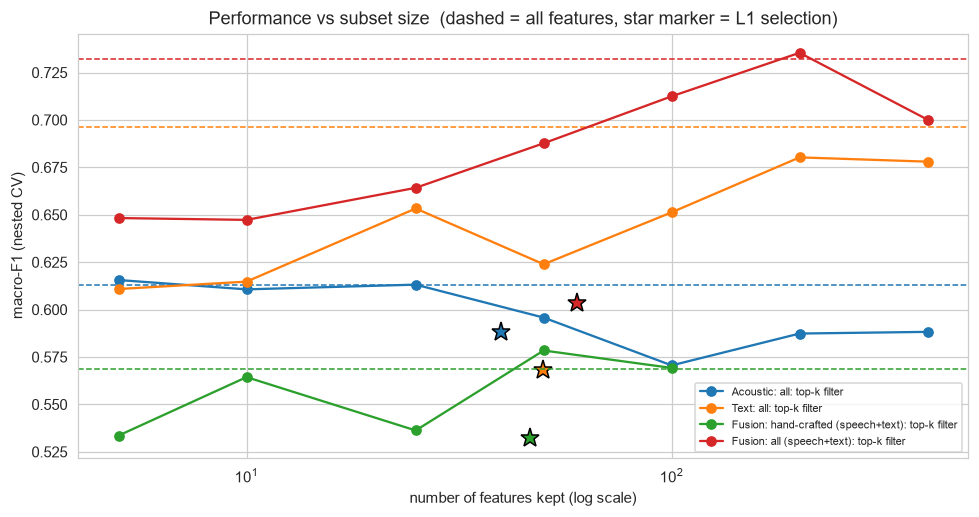

In [17]:
rows = []
for mod in RQ3_MODS:
    rows.append({"features": MOD_LABEL[mod], "method": "all features", "k": len(cols_of(mod)), **summarize(RESULTS[BEST_CFG[mod]])})
    for k in K_GRID:
        if f"{mod}|k{k}" in RESULTS:
            rows.append({"features": MOD_LABEL[mod], "method": "filter (ANOVA)", "k": k, **summarize(RESULTS[f"{mod}|k{k}"])})
    s = summarize(RESULTS[f"{mod}|l1"])
    rows.append({"features": MOD_LABEL[mod], "method": "embedded (L1)", "k": s["n_features"], **s})
rq3 = pd.DataFrame(rows)
rq3.round(4).to_csv(OUT_DIR / "rq3_compact_subsets.csv", index=False)

ans = []
for mod in RQ3_MODS:
    sub = rq3[rq3["features"] == MOD_LABEL[mod]]
    full = sub[sub["method"] == "all features"].iloc[0]
    ok = sub[(sub["method"] != "all features") & (sub["macro_f1"] >= full["macro_f1"] - 0.02)].sort_values("k")
    b = ok.iloc[0] if len(ok) else None
    ans.append({"features": MOD_LABEL[mod], "full_k": int(full["k"]), "full_macro_f1": full["macro_f1"],
                "compact_method": b["method"] if b is not None else "none",
                "compact_k": int(round(b["k"])) if b is not None else np.nan,
                "compact_macro_f1": b["macro_f1"] if b is not None else np.nan})
rq3_answer = pd.DataFrame(ans).set_index("features")
rq3_answer["reduction"] = (1 - rq3_answer["compact_k"] / rq3_answer["full_k"]).map(lambda v: f"{v:.1%}" if pd.notna(v) else "—")
display(rq3_answer.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, mod in enumerate(RQ3_MODS):
    sub = rq3[(rq3["features"] == MOD_LABEL[mod]) & (rq3["method"] == "filter (ANOVA)")]
    full = rq3[(rq3["features"] == MOD_LABEL[mod]) & (rq3["method"] == "all features")].iloc[0]
    l1 = rq3[(rq3["features"] == MOD_LABEL[mod]) & (rq3["method"] == "embedded (L1)")].iloc[0]
    c = f"C{i}"
    ax.plot(sub["k"], sub["macro_f1"], "o-", color=c, label=f"{MOD_LABEL[mod]}: top-k filter")
    ax.axhline(full["macro_f1"], color=c, ls="--", lw=1)
    ax.plot(l1["k"], l1["macro_f1"], "*", ms=13, color=c, mec="k")
ax.set_xscale("log"); ax.set_xlabel("number of features kept (log scale)"); ax.set_ylabel("macro-F1 (nested CV)")
ax.set_title("Performance vs subset size  (dashed = all features, star marker = L1 selection)")
ax.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "08_subset_size.png", bbox_inches="tight"); plt.show()

,macro_f1,macro_f1_sd,auc,recall_dep,precision_dep
1 default,0.701,0.063,0.785,0.492,0.674
2 + class weighting,0.712,0.060,0.787,0.553,0.663
3 + hyper-parameter tuning,0.707,0.060,0.784,0.565,0.642
4 + threshold tuning,0.717,0.077,0.784,0.578,0.664
5 + SMOTE,0.732,0.087,0.792,0.601,0.650
6 + top-200 feature selection,0.735,0.065,0.789,0.615,0.686


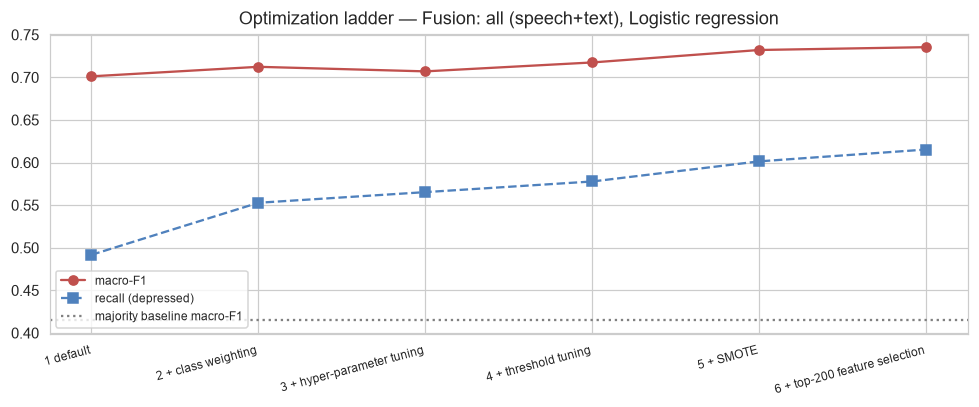

In [18]:
# Last optimization step: add the best subset size for the ladder's feature set
sub = rq3[(rq3["features"] == MOD_LABEL[LADDER_MOD]) & (rq3["method"] == "filter (ANOVA)")].sort_values("macro_f1", ascending=False)
if len(sub) and sub.iloc[0]["macro_f1"] > summarize(ladder[-1][1])["macro_f1"]:
    ladder.append((f"{len(ladder) + 1} + top-{int(sub.iloc[0]['k'])} feature selection", RESULTS[f"{LADDER_MOD}|k{int(sub.iloc[0]['k'])}"]))
lad = pd.DataFrame({name: summarize(df) for name, df in ladder}).T
display(lad[["macro_f1", "macro_f1_sd", "auc", "recall_dep", "precision_dep"]].round(3))
lad.round(4).to_csv(OUT_DIR / "optimization_ladder.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(lad)), lad["macro_f1"], "o-", color="#c0504d", label="macro-F1")
ax.plot(range(len(lad)), lad["recall_dep"], "s--", color="#4f81bd", label="recall (depressed)")
ax.axhline(RESULTS["majority"]["macro_f1"].mean(), color="grey", ls=":", label="majority baseline macro-F1")
ax.set_xticks(range(len(lad))); ax.set_xticklabels(lad.index, rotation=15, ha="right", fontsize=8)
ax.set_title(f"Optimization ladder — {MOD_LABEL[LADDER_MOD]}, {CLF_LABEL[LADDER_CLF]}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_optimization_ladder.png", bbox_inches="tight"); plt.show()

## 9. Stability and Interpretability of Selected Features (RQ4)

A compact subset is useful only if roughly **the same features are chosen every time**. We repeat the selection on **25 training sets** (5 random seeds × 5 folds of the development pool) and measure agreement with the **Nogueira stability index** (1 = identical subsets, 0 = no better than random) and the mean pairwise **Jaccard** similarity.

We do this for (a) the full speech + text feature set, and (b) the **hand-crafted** speech + text set, whose features have names and can be interpreted.

In [19]:
def nogueira(Z):
    Z = np.asarray(Z, dtype=float); M, d = Z.shape; kbar = Z.sum(1).mean()
    if kbar in (0, d):
        return np.nan
    s2 = M / (M - 1) * Z.mean(0) * (1 - Z.mean(0))
    return 1 - s2.mean() / ((kbar / d) * (1 - kbar / d))

def mean_jaccard(Z):
    Z = np.asarray(Z, dtype=bool)
    return float(np.mean([(a & b).sum() / max((a | b).sum(), 1) for a, b in combinations(Z, 2)]))

def selection_masks(mod, method, k=None, C=None, seeds=range(5)):
    X, cols = Xdev(mod), np.array(cols_of(mod))
    masks = []
    for s in seeds:
        for tr_i, _ in StratifiedKFold(5, shuffle=True, random_state=s).split(X, y_dev):
            Xi = SimpleImputer(strategy="median").fit_transform(X[tr_i])
            var = VarianceThreshold(1e-8).fit(Xi)
            Xs = StandardScaler().fit_transform(var.transform(Xi))
            kept = cols[var.get_support()]
            if method == "filter":
                sel = SelectKBest(f_classif, k=min(k, Xs.shape[1])).fit(Xs, y_dev[tr_i]).get_support()
            else:
                sel = LogisticRegression(penalty="l1", solver="liblinear", C=C, class_weight="balanced", max_iter=5000,
                                         random_state=SEED).fit(Xs, y_dev[tr_i]).coef_.ravel() != 0
            masks.append(np.isin(cols, kept[sel]))
    return np.array(masks), cols

def compact_k(mod, default):
    r = rq3_answer.loc[MOD_LABEL[mod]]
    return int(r["compact_k"]) if r["compact_method"] == "filter (ANOVA)" else default

stab_rows, FREQ = [], {}
for mod, default_k in [("early_fusion", 100), ("handcrafted", 25)]:
    C_l1 = pd.Series([json.loads(p)["clf__C"] for p in RESULTS[f"{mod}|l1"]["params"]]).mode()[0]
    for method, kw in [("filter (ANOVA)", {"k": compact_k(mod, default_k)}), ("embedded (L1)", {"C": C_l1})]:
        Z, cols = selection_masks(mod, "filter" if method.startswith("filter") else "l1", **kw)
        FREQ[(mod, method)] = pd.Series(Z.mean(0), index=cols)
        stab_rows.append({"feature set": MOD_LABEL[mod], "method": method,
                          "setting": f"k={kw['k']}" if "k" in kw else f"C={C_l1}",
                          "avg features selected": Z.sum(1).mean(), "Nogueira stability": nogueira(Z),
                          "mean Jaccard": mean_jaccard(Z), "chosen in ≥80% of runs": int((Z.mean(0) >= 0.8).sum())})
rq4 = pd.DataFrame(stab_rows).set_index(["feature set", "method"])
display(rq4.round(3))
rq4.round(4).to_csv(OUT_DIR / "rq4_stability.csv")

setting  avg features selected  Nogueira stability  mean Jaccard  chosen in ≥80% of runs
feature set                        method                                                                                                 
Fusion: all (speech+text)          filter (ANOVA)   k=100                 100.00               0.520         0.369                      32
                                   embedded (L1)    C=1.0                  69.16               0.302         0.189                       6
Fusion: hand-crafted (speech+text) filter (ANOVA)    k=10                  10.00               0.451         0.334                       5
                                   embedded (L1)    C=1.0                  51.08               0.435         0.465                      27

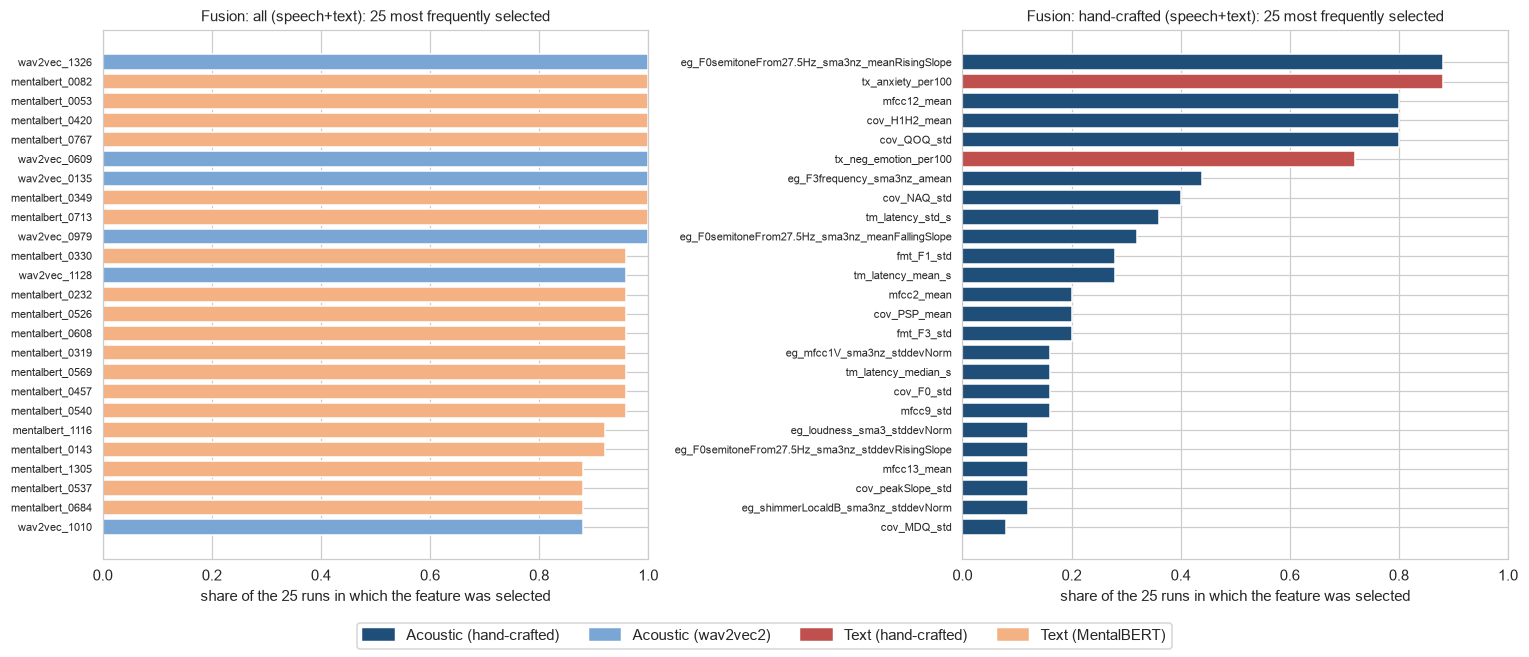

,Fusion: all (speech+text) / filter (ANOVA),Fusion: all (speech+text) / embedded (L1),Fusion: hand-crafted (speech+text) / filter (ANOVA),Fusion: hand-crafted (speech+text) / embedded (L1)
"features selected in ≥ 50% of runs, by block",,,,
Acoustic (hand-crafted),2,2,4,31
Acoustic (wav2vec2),16,3,0,0
Text (MentalBERT),58,24,0,0
Text (hand-crafted),0,0,2,10


In [20]:
def block_of(col):
    for b, cs in block_cols.items():
        if col in cs:
            return b
BLOCK_COLOR = {"acoustic_hc": "#1f4e79", "acoustic_w2v": "#7aa6d6", "text_hc": "#c0504d", "text_bert": "#f4b183", "video": "#8064a2"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, key in zip(axes, [("early_fusion", "filter (ANOVA)"), ("handcrafted", "filter (ANOVA)")]):
    top = FREQ[key].sort_values(ascending=False).head(25)[::-1]
    ax.barh(top.index, top.values, color=[BLOCK_COLOR[block_of(c)] for c in top.index])
    ax.set_xlim(0, 1); ax.set_xlabel("share of the 25 runs in which the feature was selected")
    ax.set_title(f"{MOD_LABEL[key[0]]}: 25 most frequently selected", fontsize=10); ax.tick_params(axis="y", labelsize=7)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=BLOCK_COLOR[b]) for b in FUSION_BLOCKS], [BLOCK_LABEL[b] for b in FUSION_BLOCKS],
           loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(FIG_DIR / "09_selection_frequency.png", bbox_inches="tight"); plt.show()

share = pd.DataFrame({f"{MOD_LABEL[m]} / {meth}": f[f >= 0.5].groupby(lambda c: BLOCK_LABEL[block_of(c)]).size()
                      for (m, meth), f in FREQ.items()}).fillna(0).astype(int)
share.index.name = "features selected in ≥ 50% of runs, by block"
display(share)

In [21]:
# Interpretation: the most stable hand-crafted features and the direction of their effect
f = FREQ[("handcrafted", "filter (ANOVA)")]
stable = f[f >= 0.6].sort_values(ascending=False).index
D = features.loc[DEV_IDS, stable]
dep, non = D[y_dev == 1], D[y_dev == 0]
pooled = np.sqrt(((len(dep) - 1) * dep.var() + (len(non) - 1) * non.var()) / (len(dep) + len(non) - 2))
interp = pd.DataFrame({"block": [BLOCK_LABEL[block_of(c)] for c in stable], "selected share": f[stable],
                       "mean depressed": dep.mean(), "mean not depressed": non.mean(),
                       "Cohen's d": (dep.mean() - non.mean()) / pooled})
interp["direction in depressed"] = np.where(interp["Cohen's d"] > 0, "higher", "lower")
display(interp.round(3))
interp.round(4).to_csv(OUT_DIR / "rq4_stable_handcrafted_features.csv")

,block,selected share,mean depressed,mean not depressed,Cohen's d,direction in depressed
eg_F0semitoneFrom27.5Hz_sma3nz_meanRisingSlope,Acoustic (hand-crafted),0.88,192.446,155.031,0.556,higher
tx_anxiety_per100,Text (hand-crafted),0.88,0.156,0.086,0.546,higher
mfcc12_mean,Acoustic (hand-crafted),0.80,-0.259,1.395,-0.502,lower
cov_QOQ_std,Acoustic (hand-crafted),0.80,0.145,0.128,0.539,higher
cov_H1H2_mean,Acoustic (hand-crafted),0.80,4.262,2.882,0.510,higher
tx_neg_emotion_per100,Text (hand-crafted),0.72,0.533,0.399,0.476,higher


## 10. Final Model Selection and One-Shot Test Evaluation

Two models are **declared before the test set is used**:

1. **Best overall**: the candidate with the highest nested-CV macro-F1 among all candidates in Sections 5–8 (video excluded, as it is outside the proposal's scope).
2. **Best compact**: the best candidate that uses **≤ 100 features**, which tests the RQ3 claim on unseen data.

Each is refit on all 141 development participants (the inner CV re-tunes hyper-parameters and the threshold) and scored **once** on the 47 test participants.

In [22]:
def describe(name):
    if name.startswith("late_fusion"):
        return ("Weighted late fusion (4 blocks)" if "weighted" in name else "Late fusion, equal weights (4 blocks)"), "early_fusion", None
    mod, rest = name.split("|", 1)
    if rest.startswith("k"):
        _, clf_name, imb = BEST_CFG[mod].split("|")
        return f"{MOD_LABEL[mod]} — {CLF_LABEL[clf_name]}, top-{rest[1:]} ANOVA features", mod, ("k", int(rest[1:]), clf_name, imb)
    if rest == "l1":
        return f"{MOD_LABEL[mod]} — L1 logistic regression", mod, ("l1",)
    clf_name, imb = rest.split("|")
    return f"{MOD_LABEL[mod]} — {CLF_LABEL[clf_name]} ({'SMOTE' if imb == 'smote' else 'class weight'})", mod, ("full", clf_name, imb)

def build(name):
    _, mod, how = describe(name)
    if name.startswith("late_fusion"):
        return LateFusion(block_specs(), weighted="weighted" in name, seed=SEED), {}, mod
    if how[0] == "k":
        est, grid = model_spec(mod, how[2], "smote" if how[3] == "smote" else "class_weight", k=how[1])
    elif how[0] == "l1":
        est, grid = l1_pipe(), L1_GRID
    else:
        est, grid = model_spec(mod, how[1], "smote" if how[2] == "smote" else "class_weight")
    return est, grid, mod

pool = [n for n in RESULTS if n != "majority" and not n.startswith("video") and not n.startswith("opt_")]
leader = pd.DataFrame({n: summarize(RESULTS[n]) for n in pool}).T
leader["description"] = [describe(n)[0] for n in leader.index]
leader = leader.sort_values("macro_f1", ascending=False)
leader.round(4).to_csv(OUT_DIR / "leaderboard_nested_cv.csv")
display(leader[["description", "macro_f1", "macro_f1_sd", "auc", "recall_dep", "n_features"]].head(12).round(3))

FINAL_OVERALL = leader.index[0]
FINAL_COMPACT = leader[leader["n_features"] <= 100].index[0]
print("Pre-declared final models:")
print("  1. best overall :", describe(FINAL_OVERALL)[0])
print("  2. best compact :", describe(FINAL_COMPACT)[0], f"(≈{leader.loc[FINAL_COMPACT, 'n_features']:.0f} features)")

,description,macro_f1,macro_f1_sd,auc,recall_dep,n_features
early_fusion|k200,Fusion: all (speech+text) — Logistic regressio...,0.735,0.065,0.789,0.615,200.0
early_fusion|logreg|smote,Fusion: all (speech+text) — Logistic regressio...,0.732,0.087,0.792,0.601,3217.0
early_fusion|logreg|cw,Fusion: all (speech+text) — Logistic regressio...,0.717,0.077,0.784,0.578,3217.0
early_fusion|k100,Fusion: all (speech+text) — Logistic regressio...,0.712,0.094,0.762,0.592,100.0
early_fusion|k400,Fusion: all (speech+text) — Logistic regressio...,0.700,0.075,0.779,0.565,400.0
text|svm|cw,Text: all — RBF-SVM (class weight),0.697,0.098,0.734,0.562,1553.0
text_bert|svm|cw,Text: MentalBERT — RBF-SVM (class weight),0.695,0.090,0.737,0.562,1536.0
early_fusion|svm|cw,Fusion: all (speech+text) — RBF-SVM (class wei...,0.691,0.094,0.747,0.540,3217.0
early_fusion|k50,Fusion: all (speech+text) — Logistic regressio...,0.688,0.089,0.720,0.529,50.0
text_bert|rf|cw,Text: MentalBERT — Random forest (class weight),0.681,0.074,0.718,0.538,1536.0


Pre-declared final models:
  1. best overall : Fusion: all (speech+text) — Logistic regression, top-200 ANOVA features
  2. best compact : Fusion: all (speech+text) — Logistic regression, top-100 ANOVA features (≈100 features)


,model,threshold,nested-CV macro-F1,test macro_f1,test auc,test bal_acc,test recall_dep,test precision_dep,test accuracy
best overall,Fusion: all (speech+text) — Logistic regressio...,0.57,0.7354,0.675862,0.720779,0.679654,0.571429,0.533333,0.723404
best compact,Fusion: all (speech+text) — Logistic regressio...,0.52,0.712448,0.631373,0.727273,0.654762,0.642857,0.45,0.659574


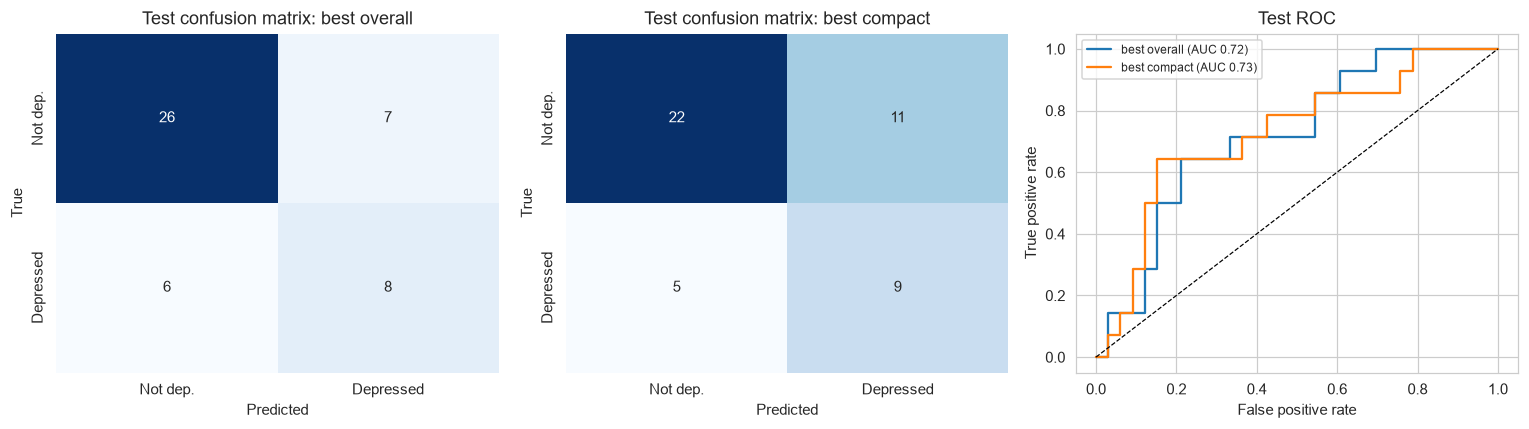

In [23]:
final = {}
for tag, name in [("best overall", FINAL_OVERALL), ("best compact", FINAL_COMPACT)]:
    est, grid, mod = build(name)
    model, thr, params = fit_tuned(est, grid, Xdev(mod), y_dev)
    p = model.predict_proba(Xtest(mod))[:, 1]
    final[tag] = {"name": name, "mod": mod, "model": model, "threshold": thr, "params": params, "prob": p,
                  "test": metrics(y_test, p, thr), "cv": summarize(RESULTS[name])}

test_tab = pd.DataFrame({tag: {"model": describe(f["name"])[0], "threshold": f["threshold"], "nested-CV macro-F1": f["cv"]["macro_f1"],
                               **{f"test {k}": v for k, v in f["test"].items()}} for tag, f in final.items()}).T
display(test_tab)
test_tab.to_csv(OUT_DIR / "test_results.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (tag, f) in zip(axes[:2], final.items()):
    cm = confusion_matrix(y_test, (f["prob"] >= f["threshold"]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Not dep.", "Depressed"], yticklabels=["Not dep.", "Depressed"])
    ax.set_title(f"Test confusion matrix: {tag}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for tag, f in final.items():
    fpr, tpr, _ = roc_curve(y_test, f["prob"])
    axes[2].plot(fpr, tpr, label=f"{tag} (AUC {f['test']['auc']:.2f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8); axes[2].legend(fontsize=8)
axes[2].set_title("Test ROC"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
plt.tight_layout(); plt.savefig(FIG_DIR / "10_final_test.png", bbox_inches="tight"); plt.show()

for tag, f in final.items():
    if isinstance(f["model"], LateFusion) and f["model"].weighted:
        print(f"{tag}: learned block weights", dict(zip([BLOCK_LABEL[b] for b in FUSION_BLOCKS], f["model"].stacker_.coef_.ravel().round(3))))

### 10.1 Error analysis by gender

Part 1 found that women in the development pool were more often depressed (37 % vs 23 %). We check whether the selected model works equally well for both groups. We use the out-of-fold predictions on the development pool, which has more participants than the test set, and also report the test set.

In [24]:
def by_gender(pids, y, prob, thr):
    g = meta.loc[pids, "gender"].map({0: "female", 1: "male"}).values
    rows = {}
    for grp in ["female", "male"]:
        m = g == grp
        rows[grp] = {"n": int(m.sum()), "depressed": int(y[m].sum()), **metrics(y[m], prob[m], thr if np.isscalar(thr) else thr[m])}
    return pd.DataFrame(rows).T

oof = PRED[RESULTS[FINAL_OVERALL].attrs["cache_name"]]
oof_y = meta.loc[oof["participant_id"], "y"].values
print("Development pool, out-of-fold predictions (best overall model; 5 folds × 2 repeats pooled, so n counts each participant twice):")
display(by_gender(oof["participant_id"].values, oof_y, oof["prob"].values, oof["threshold"].values).round(3))
print("Test set (best overall model):")
display(by_gender(TEST_IDS, y_test, final["best overall"]["prob"], final["best overall"]["threshold"]).round(3))

Development pool, out-of-fold predictions (best overall model; 5 folds × 2 repeats pooled, so n counts each participant twice):


,n,depressed,macro_f1,auc,bal_acc,recall_dep,precision_dep,accuracy
female,124.0,46.0,0.821,0.901,0.825,0.804,0.755,0.831
male,158.0,36.0,0.628,0.608,0.619,0.361,0.464,0.759


Test set (best overall model):


,n,depressed,macro_f1,auc,bal_acc,recall_dep,precision_dep,accuracy
female,24.0,7.0,0.625,0.681,0.639,0.571,0.444,0.667
male,23.0,7.0,0.732,0.804,0.723,0.571,0.667,0.783


## 11. Complete Machine-Learning Pipeline

The final pipeline, end to end:

```
raw interview (audio + transcript)
  └─ Part 1 extraction: participant speech only → hand-crafted acoustic + linguistic features
  └─ pre-computed wav2vec2 / MentalBERT embeddings (if the model uses them)
       └─ saved model: impute → scale → [select] → classifier  (+ fusion)
            └─ probability of depression → threshold → screening decision
```

The best-overall model is saved with its threshold and the exact columns (and source files) it expects. `predict.py` reloads it for new participants. Below we verify the pipeline end to end on the test participants: its output must match the notebook's predictions exactly.

In [25]:
f = final["best overall"]
cols = cols_of(f["mod"])
sources = {}
for c in cols:
    sources.setdefault(block_file[block_of(c)], []).append(c)
bundle = {"model": f["model"], "threshold": f["threshold"], "columns": cols, "sources": sources,
          "description": describe(f["name"])[0], "trained_on": "DAIC-WOZ train+dev (141 participants)", "target": "PHQ-8 >= 10"}
joblib.dump(bundle, OUT_DIR / "final_model.joblib")
print("Saved", OUT_DIR / "final_model.joblib", "—", bundle["description"], "| inputs:", {k: len(v) for k, v in sources.items()})

import predict
importlib.reload(predict)
pred = predict.predict([DATA_ROOT, PART1_FEATURES.parent], OUT_DIR / "final_model.joblib", ids=TEST_IDS)
assert np.allclose(pred["probability_depressed"].values, np.round(f["prob"], 4))
print("PASS: predict.py reproduces the notebook's test predictions.\n")
display(pred.head(8))

Saved part2_outputs\final_model.joblib — Fusion: all (speech+text) — Logistic regression, top-200 ANOVA features | inputs: {'features_master.csv': 145, 'DAIC_WOZ_wav2vec2_temporal_1536.csv': 1536, 'DAIC_WOZ_MentalBERT_1536.csv': 1536}


PASS: predict.py reproduces the notebook's test predictions.



,participant_id,probability_depressed,screen_positive
0,300,0.0571,0
1,301,0.1300,0
2,306,0.0089,0
3,308,0.1847,0
4,309,0.1583,0
5,311,0.5487,0
6,314,0.5817,1
7,323,0.1225,0


## 12. Answers to the Research Questions

In [26]:
majf = RESULTS["majority"]["macro_f1"].mean()
ac = rq2.loc[[MOD_LABEL[m] for m in ["acoustic_hc", "acoustic_w2v", "acoustic"]], ["macro_f1", "auc"]]
tx = rq2.loc[[MOD_LABEL[m] for m in ["text_hc", "text_bert", "text"]], ["macro_f1", "auc"]]
fus = rq2.loc[fusion_names, "macro_f1"]
best_f = fus.idxmax()
diff = RESULTS[cands[best_f]]["macro_f1"].values - RESULTS[BEST_SINGLE]["macro_f1"].values
gain, wins = diff.mean(), int((diff > 0).sum())
verdict = ("Fusion helps consistently." if gain > 0.02 and wins >= 8 else
           f"A small gain, better in {wins}/10 folds; given a fold-to-fold SD of ≈{rq2['macro_f1_sd'].iloc[1:].mean():.2f} this is suggestive, not conclusive." if gain > 0
           else "Fusion does not beat the best single modality.")
hc = rq3_answer.loc[MOD_LABEL["handcrafted"]]; ef = rq3_answer.loc[MOD_LABEL["early_fusion"]]
fo, fc = final["best overall"], final["best compact"]
def rq3_line(r, name):
    if r["compact_method"] == "none":
        return f"{name}: no subset stayed within 2 points of all {r['full_k']} features ({r['full_macro_f1']:.3f})"
    return (f"{name}: {r['compact_method']} with ~{r['compact_k']} of {r['full_k']} features reaches "
            f"{r['compact_macro_f1']:.3f} vs {r['full_macro_f1']:.3f} ({r['reduction']} fewer)")
lines = [
 f"RQ1  Yes. Majority baseline {majf:.3f}. Acoustic: hand-crafted {ac.iloc[0, 0]:.3f}, wav2vec2 {ac.iloc[1, 0]:.3f}, both {ac.iloc[2, 0]:.3f}. "
 f"Text: hand-crafted {tx.iloc[0, 0]:.3f}, MentalBERT {tx.iloc[1, 0]:.3f}, both {tx.iloc[2, 0]:.3f}.",
 f"RQ2  Best fusion: {best_f} ({fus.max():.3f}) vs best single modality {single_scores.idxmax()} ({single_scores.max():.3f}): "
 f"{gain:+.3f}. {verdict}",
 "RQ3  " + rq3_line(ef, "All speech+text") + "; " + rq3_line(hc, "hand-crafted speech+text") + ".",
 "RQ4  Nogueira stability — " + "; ".join(f"{fs} / {m}: {r['Nogueira stability']:.2f} ({r['chosen in ≥80% of runs']} features chosen in ≥80% of runs)"
                                        for (fs, m), r in rq4.iterrows()) + ".",
 f"TEST Best overall ({describe(fo['name'])[0]}): macro-F1 {fo['test']['macro_f1']:.3f}, AUC {fo['test']['auc']:.3f}, "
 f"recall {fo['test']['recall_dep']:.3f}. Best compact ({describe(fc['name'])[0]}): macro-F1 {fc['test']['macro_f1']:.3f}, "
 f"AUC {fc['test']['auc']:.3f}, recall {fc['test']['recall_dep']:.3f}."
 + (" The two models swap order between cross-validation and test; with 47 test participants (14 depressed) one person "
    "moves macro-F1 by ~0.02–0.04, so the test set alone cannot separate them."
    if (fc['test']['macro_f1'] > fo['test']['macro_f1']) != (fc['cv']['macro_f1'] > fo['cv']['macro_f1']) else ""),
]
print("\n\n".join(lines))
_ = (OUT_DIR / "answers.txt").write_text("\n\n".join(lines), encoding="utf-8")

RQ1  Yes. Majority baseline 0.415. Acoustic: hand-crafted 0.572, wav2vec2 0.573, both 0.613. Text: hand-crafted 0.514, MentalBERT 0.695, both 0.697.

RQ2  Best fusion: Early fusion (all) (0.732) vs best single modality Text: all (0.697): +0.036. A small gain, better in 6/10 folds; given a fold-to-fold SD of ≈0.09 this is suggestive, not conclusive.

RQ3  All speech+text: filter (ANOVA) with ~100 of 3217 features reaches 0.712 vs 0.732 (96.9% fewer); hand-crafted speech+text: filter (ANOVA) with ~10 of 145 features reaches 0.564 vs 0.569 (93.1% fewer).

RQ4  Nogueira stability — Fusion: all (speech+text) / filter (ANOVA): 0.52 (32 features chosen in ≥80% of runs); Fusion: all (speech+text) / embedded (L1): 0.30 (6 features chosen in ≥80% of runs); Fusion: hand-crafted (speech+text) / filter (ANOVA): 0.45 (5 features chosen in ≥80% of runs); Fusion: hand-crafted (speech+text) / embedded (L1): 0.44 (27 features chosen in ≥80% of runs).

TEST Best overall (Fusion: all (speech+text) — Logis

### Limitations

- **Small sample.** 141 development and 47 test participants; fold-to-fold standard deviations of macro-F1 (≈ 0.07–0.10) should be read alongside every mean.
- **Pre-computed embeddings.** The wav2vec2 and MentalBERT features were extracted outside these notebooks; we assume they were computed from participant speech only, consistent with Part 1's rule against interviewer-prompt shortcuts.
- **Labels.** PHQ-8 is a self-report questionnaire; the official label of one participant (409) disagrees with the ≥ 10 rule and is kept for comparability with published work.
- **Screening aid only.** The system flags participants for follow-up; it does not diagnose.